In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
import matplotlib.pyplot as plt
GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['cmr10']
plt.rcParams['mathtext.fontset'] = 'cm'

## Procedure

1. Set up the load cell, tie the string to the tip, and run `python3 ../LoadCell/arduino_force.py`.
2. Set the config to use a tanh spring:

```
component=VirtualComponent(
    spring=TanhSpring(10.0, 1.33),
    damper=LinearDamper(1.5),
    s_param=1.0,
    name="lin_seg3",
),
goal=go_x_y,
```

3. `python3 Sequential_jump_tests.py`

The recorded runs used K = 10 N/m and F_max = 1.33 N (the shipped config has
`TanhSpring(15.0, 1.5)`); the linear run is the same with `spring=LinearSpring(10.0)`.

# Tanh vs Linear Spring — Saturation Comparison

## Force law

`TanhSpring.compute_force` (`VMC_utils/VirtualModels.py`) implements

$$F = F_{max} \tanh\!\left(\frac{K\,e}{F_{max}}\right), \qquad e = x_{target} - x_{current}$$

with $K$ = `stiffness` (10 N/m here, matched to the Linear spring below) and
$F_{max}$ = `max_force` (1.33 N here).

- **Near the origin** ($e \to 0$): $\tanh(z) \approx z$, so $F \approx K e$ — it behaves
  exactly like a linear spring with slope $K$ for small displacements.
- **Far out** ($e \to \infty$): $\tanh(z) \to 1$, so $F \to F_{max}$ — the force
  saturates no matter how large the error gets, unlike the linear spring's unbounded
  $F = Ke$. That's the entire point of the comparison below.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

F_MAX = 1.33                # tanh saturation limit [N]
VIRTUAL_FORCE_YMAX = 1.5    # [N] fixed y-axis upper bound for the virtual-force panel
MEASURED_FORCE_YMAX = 2.0   # [N] fixed y-axis upper bound for the Tanh-vs-Linear measured-force panel
K_RETURN = 66.667    # snap-back stiffness to exclude
SS_FRAC = 0.40       # fraction (tail) of each window used for steady-state
G_TO_N = 9.80665e-3  # load cell outputs grams → convert to Newtons

files = {
    "Tanh (Fmax=1.33)": "outputs/tanh_spring/tanh_k10.npz",
    "Linear":           "outputs/tanh_spring/linear_k10.npz",
}

# Virtual vs. measured force (both are the Tanh spring's own two readings) --
# warm family so they read as related, but pushed further apart on the
# orange <-> red-wine axis so they're clearly distinguishable. Both are also
# used as text color (axis label + ticks), so kept dark enough to stay
# readable, not just visible as a line.
COLOR_VIRTUAL  = '#A85A1B'   # burnt orange -- virtual (model) force
COLOR_MEASURED = '#8B2E3F'   # deep wine red -- measured (load cell) force

# Tanh vs. Linear comparison colors below: Tanh reuses COLOR_MEASURED because
# it's the same quantity (Tanh's measured force) as the plot above, so that
# series' identity stays consistent across both plots. Linear keeps its own
# distinct, unrelated color.
COLOR_TANH   = COLOR_MEASURED
COLOR_LINEAR = '#4F7C96'   # cool steel blue
colors = {"Tanh (Fmax=1.33)": COLOR_TANH, "Linear": COLOR_LINEAR}

# Shared text size for axis labels, tick labels, legend, and the F_max
# annotation across both force plots below, so the two figures read as one
# consistent pair.
SHARED_LABEL_SIZE = LEGEND_FONT_SIZE * 1.5



def extract_windows(fn):
    """Return per-target hold windows, excluding the snap-back phases."""
    d = np.load(fn, allow_pickle=True)
    t      = d["t"]
    k      = d["k_params"][:, 0]
    goalx  = d["goal"][:, 0, 0]
    posx   = d["comp_pos"][:, 0, 0]
    fx     = d["f_virtual"][:, 0]
    fmag   = np.linalg.norm(d["f_virtual"], axis=1)
    force  = d["force"] * G_TO_N              # load cell: grams → convert to Newtons

    # mask = test phases (anything that is NOT the snap-back stiffness)
    mask = ~np.isclose(k, K_RETURN)
    edges = np.diff(mask.astype(int))
    starts = np.where(edges == 1)[0] + 1
    ends   = np.where(edges == -1)[0] + 1
    if mask[0]:  starts = np.r_[0, starts]
    if mask[-1]: ends   = np.r_[ends, len(mask)]

    wins = []
    for s, e in zip(starts, ends):
        if e - s < 10:
            continue
        target = round(np.median(goalx[s:e]) / 0.05) * 0.05   # snap to 5cm grid
        if abs(target) < 1e-6:
            continue
        tail = slice(s + int((1 - SS_FRAC) * (e - s)), e)
        wins.append(dict(
            target=target,
            t=t[s:e] - t[s],          # time since jump
            goalx=goalx[s:e],
            posx=posx[s:e],
            fx=fx[s:e],
            fmag=fmag[s:e],
            force=force[s:e],                         # measured shear force [N]
            fx_ss=np.mean(fx[tail]),
            posx_ss=np.mean(posx[tail]),
            fmag_ss=np.mean(fmag[tail]),
            force_ss=np.mean(np.abs(force[tail])),    # steady-state measured force [N]
        ))
    wins.sort(key=lambda w: -w["target"])   # -0.05 first ... -0.50 last
    return wins


data = {name: extract_windows(fn) for name, fn in files.items()}
for name, wins in data.items():
    print(f"{name}: {len(wins)} test windows  "
          f"(targets {wins[0]['target']:.2f} … {wins[-1]['target']:.2f} m)")

# Shared axis ranges/ticks so the two force plots below line up exactly
DISP_MAX = max(abs(w["target"]) for wins in data.values() for w in wins) * 100  # [cm]
X_TICK_STEP = 10       # [cm] shared "Commanded displacement" tick spacing
FORCE_TICK_STEP = 0.2  # [N]  shared "measured force" tick spacing

Tanh (Fmax=1.33): 10 test windows  (targets -0.05 … -0.50 m)
Linear: 10 test windows  (targets -0.05 … -0.50 m)


In [3]:
MEASURED_FORCE_YMAX = 1.0
FIRST_FORCE_TICK_STEP = 0.5

## 1. Virtual vs. Measured force — Tanh

The controller's **virtual force** (what the model commands) is compared against the
**measured shear force** from the load cell. Both are drawn on one axis, in newtons.
The measured force is lower than the virtual one, so it is also drawn divided by a constant
η = 0.55 (set in the code below) to compare the **shape**: both the commanded and the
physically measured force **saturate together** as displacement grows.

<>:20: SyntaxWarning: invalid escape sequence '\e'
<>:20: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_16255/2326109569.py:20: SyntaxWarning: invalid escape sequence '\e'
  ax.plot(disp, f_real_scaled, "--", color=COLOR_MEASURED, linewidth=2.0, label="Measured / $\eta$")
/tmp/ipykernel_16255/2326109569.py:16: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.6))


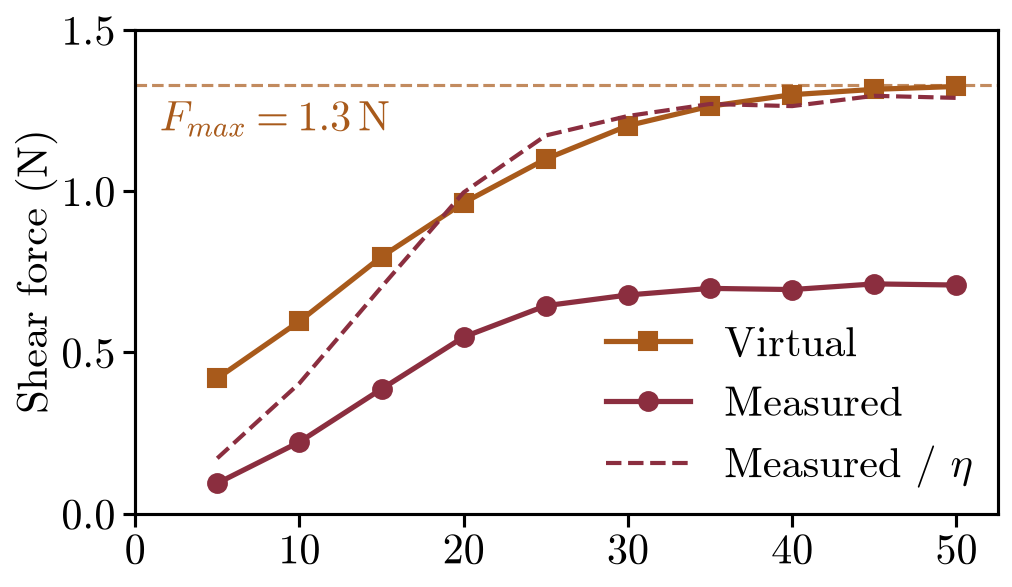

→ Virtual force caps at F_max; measured shear force plateaus around ~0.71 N.


In [4]:
def plot_virtual_vs_real(name):
    wins = data[name]
    disp     = np.array([abs(w["target"]) for w in wins]) * 100
    f_virt   = np.array([abs(w["fx_ss"]) for w in wins])
    f_real   = np.array([w["force_ss"] for w in wins])
    f_real_scaled = f_real / 0.55

    # 'standard' (not the repo-wide 'tight') keeps the full, fixed figsize
# canvas -- 'tight' crops each PDF to its own ink extent, which would crop
# this figure wider than the one below (ax2's label sticks out past
# axes_box on the right) and silently undo the box-matching below. This
# must be set as the savefig.bbox rcParam (via rc_context) -- passing
# bbox_inches='standard' directly to savefig() is invalid (it only accepts
# None, 'tight', or a Bbox) and raises AttributeError.
    with plt.rc_context({'savefig.bbox': 'standard'}):
        fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.6))

        ax.plot(disp, f_virt, "s-", color=COLOR_VIRTUAL, linewidth=2.5, markersize=9, label="Virtual")
        ax.plot(disp, f_real, "o-", color=COLOR_MEASURED, linewidth=2.5, markersize=9, label="Measured")
        ax.plot(disp, f_real_scaled, "--", color=COLOR_MEASURED, linewidth=2.0, label="Measured / $\eta$")
        #ax.set_xlabel("Commanded displacement (cm)", fontsize=SHARED_LABEL_SIZE)
        ax.set_ylabel("Shear force (N)", fontsize=SHARED_LABEL_SIZE)
        ax.tick_params(axis="both", labelsize=SHARED_LABEL_SIZE)
        ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
        ax.yaxis.set_major_locator(MultipleLocator(FIRST_FORCE_TICK_STEP))
        ax.set_xlim(0, DISP_MAX * 1.05)
        ax.set_ylim(0, VIRTUAL_FORCE_YMAX)
        if "Tanh" in name:
            ax.axhline(F_MAX, color=COLOR_VIRTUAL, linestyle="--", linewidth=1.5, alpha=0.7)
            ax.text(disp.max() * 0.03, F_MAX - 0.05, rf'$F_{{max}} = {F_MAX:.1f}\,\mathrm{{N}}$',
                    ha='left', va='top', color=COLOR_VIRTUAL, fontsize=SHARED_LABEL_SIZE)

        ax.grid(GRID)
        ax.legend(loc="lower right", fontsize=SHARED_LABEL_SIZE)
        plt.tight_layout()
        pos = ax.get_position()
        axes_box = (pos.x0, pos.y0, pos.width, pos.height)
        slug = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("=", "").replace(".", "")
        plt.savefig(os.path.join('outputs', 'tanh_spring', f'virtual_vs_real_{slug}.pdf'))
        plt.savefig(os.path.join('outputs', 'tanh_spring', f'virtual_vs_real_{slug}.png'), dpi=300)
        plt.show()
    return axes_box



AXES_BOX = plot_virtual_vs_real("Tanh (Fmax=1.33)")
print("→ Virtual force caps at F_max; measured shear force plateaus around ~0.71 N.")

## 2. Measured shear force — Tanh vs. Linear

The decisive real-world result: both measured on the **same load cell, same scale**.
The tanh spring's physical force **plateaus (~0.71 N)** while the linear spring's force
**keeps rising (~0.94 N and climbing)** — the saturation designed into the virtual
model is genuinely realized in hardware.

/tmp/ipykernel_16255/3821567039.py:4: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.6))


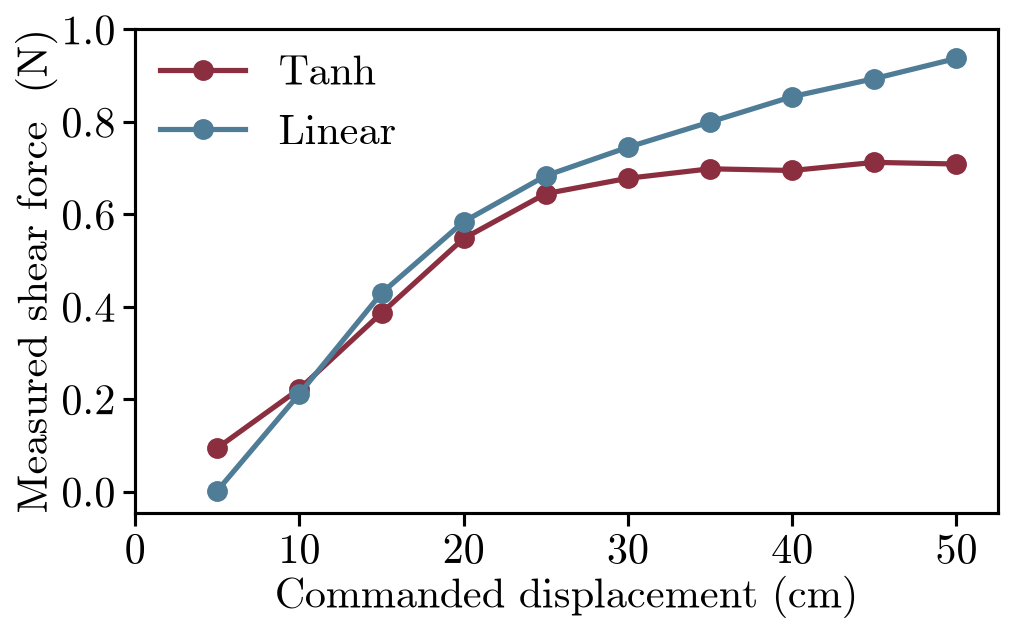

→ Physical proof: tanh shear force plateaus; linear shear force keeps growing.


In [5]:
LEGEND_LABELS = {"Tanh (Fmax=1.33)": "Tanh", "Linear": "Linear"}

with plt.rc_context({'savefig.bbox': 'standard'}):
    fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.6))

    all_f_real = []
    for name, wins in data.items():
        disp   = np.array([abs(w["target"]) for w in wins]) * 100
        f_real = np.array([w["force_ss"] for w in wins])
        all_f_real.append(f_real)
        ax.plot(disp, f_real, "o-", color=colors[name], linewidth=2.5,
                markersize=9, label=LEGEND_LABELS[name])

    # A little headroom below 0 -- the Linear series' smallest-displacement point
    # sits right at f_real≈0, and pinning the axis exactly there clips its marker
    # in half against the bottom spine.
    f_max = np.concatenate(all_f_real).max()
    y_pad = 0.05 * f_max

    ax.set_xlabel("Commanded displacement (cm)", fontsize=SHARED_LABEL_SIZE)
    ax.set_ylabel("Measured shear force  (N)", fontsize=SHARED_LABEL_SIZE)
    ax.tick_params(axis="both", labelsize=SHARED_LABEL_SIZE)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(FORCE_TICK_STEP))
    ax.set_xlim(0, DISP_MAX * 1.05)
    ax.set_ylim(-y_pad, MEASURED_FORCE_YMAX)
    ax.grid(GRID)
    ax.legend(loc="upper left", fontsize=SHARED_LABEL_SIZE)
    plt.tight_layout()
    # Pin this single-axis plot's box to the exact same (left, bottom, width,
    # height) as the dual-axis plot above -- without the second y-axis eating
    # space on its right, this box would otherwise be a different size.
    ax.set_position(AXES_BOX)
    plt.savefig(os.path.join('outputs', 'tanh_spring', 'measured_force_vs_displacement.pdf'))
    plt.savefig(os.path.join('outputs', 'tanh_spring', 'measured_force_vs_displacement.png'), dpi=300)
    plt.show()

print("→ Physical proof: tanh shear force plateaus; linear shear force keeps growing.")